# 03 · Churn Model Development and Evaluation
**RetailPulse 360 — predicting `churn_90d` (no purchase in the next 90 days)**

Covers **model development & evaluation**: baselines, four tuned models, a time-based train / validation / test design, leakage-free pipelines, model comparison, final-model justification, interpretation and limitations.

Reusable code lives in `src/retailpulse/modeling.py` (unit-tested); this notebook runs it step by step.

In [1]:
import sys, os, json, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import joblib
import sklearn
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score
from sklearn.inspection import permutation_importance
from sklearn.tree import export_text

from src.retailpulse.cleaning import load_clean
from src.retailpulse.features import build_snapshots, TARGET, NUMERIC_FEATURES
from src.retailpulse import modeling as M
from src.retailpulse import viz
from src.retailpulse.config import MODELS, REPORTS, RANDOM_STATE

viz.set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 160)
print("scikit-learn", sklearn.__version__, "| random_state =", RANDOM_STATE)

scikit-learn 1.9.1 | random_state = 42


## 1. Labelled customer snapshots and the time-based split
One snapshot = one customer at one monthly cutoff. A random row split would let the model learn from a customer's *future* months and test on their *past*, so we split **by time**:

* **Train** – cutoffs Dec 2010 – Mar 2011: the only cutoffs whose 90-day outcome is fully known by the validation date.
* **Validation** – cutoff 1 Jun 2011: hyper-parameter tuning, model selection and threshold choice.
* **Test** – cutoff 1 Sep 2011: used **once**, at the end.
* **Final refit** – before testing, the chosen settings are re-trained on every cutoff whose outcome is known by 1 Sep 2011 (Dec 2010 – Jun 2011), exactly what a business would do in production.

In [2]:
t0 = time.time()
snaps = build_snapshots(load_clean(), M.ALL_CUTOFFS)
S = M.split(snaps)
print(f"Built {len(snaps):,} snapshots in {time.time() - t0:.0f}s")
summary = pd.DataFrame({k: {"cutoffs": ", ".join(sorted({c.strftime('%Y-%m') for c in v['cutoff']})),
                            "rows": len(v), "customers": v['Customer ID'].nunique(),
                            "churn rate": v[TARGET].mean()} for k, v in S.items()}).T
summary

Built 42,832 snapshots in 48s


,cutoffs,rows,customers,churn rate
train,"2010-12, 2011-01, 2011-02, 2011-03",16914,4510,0.6558
val,2011-06,4324,4324,0.6339
refit,"2010-12, 2011-01, 2011-02, 2011-03, 2011-04, 2...",29871,4906,0.6416
test,2011-09,4323,4323,0.5047


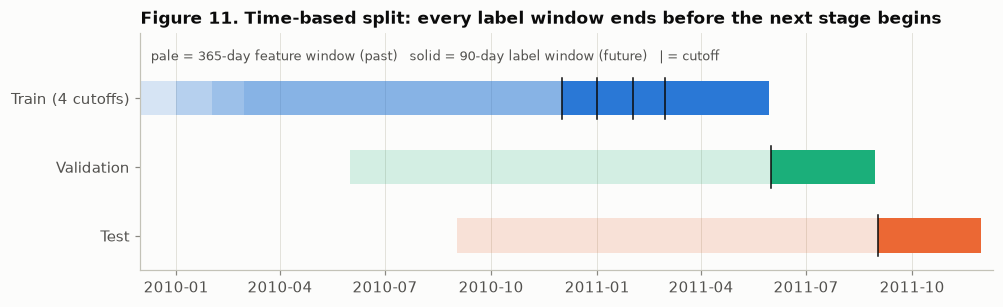

In [3]:
fig, ax = plt.subplots(figsize=(10, 2.8))
roles = [("Train", M.TRAIN_CUTOFFS, viz.BLUE, 2), ("Validation", [M.VAL_CUTOFF], viz.AQUA, 1),
         ("Test", [M.TEST_CUTOFF], viz.ORANGE, 0)]
for name, cuts, color, y in roles:
    for c in cuts:
        ax.barh(y, -365, left=c, height=0.5, color=color, alpha=0.18)          # feature window
        ax.barh(y, 90, left=c, height=0.5, color=color)                          # label window
        ax.plot([c, c], [y - 0.3, y + 0.3], color=viz.INK, lw=1)
ax.set_yticks([2, 1, 0], ["Train (4 cutoffs)", "Validation", "Test"]); ax.grid(axis="y", visible=False)
ax.set_xlim(pd.Timestamp("2009-12-01"), pd.Timestamp("2011-12-10"))
ax.set_ylim(-0.5, 2.95)
ax.text(pd.Timestamp("2009-12-10"), 2.55, "pale = 365-day feature window (past)   solid = 90-day label window (future)   | = cutoff",
        fontsize=8.5, color=viz.INK_2)
ax.set_title("Figure 11. Time-based split: every label window ends before the next stage begins")
viz.save(fig, "fig11_time_split"); plt.show()

## 2. Baselines

* **Majority-class (Dummy)** – predicts *churn* for everyone. Any useful model must beat it.
* **Recency rule** – a simple business rule: *"no order in the last 90 days ⇒ churn"*. If ML cannot beat this, it is not worth deploying.

In [4]:
Xtr, ytr = S["train"][M.FEATURES], S["train"][TARGET]
Xva, yva = S["val"][M.FEATURES], S["val"][TARGET]
val_rows, val_proba = {}, {}

dummy = M.make_dummy().fit(Xtr, ytr)
val_proba["Baseline: majority class"] = dummy.predict_proba(Xva)[:, 1]
val_rows["Baseline: majority class"] = M.evaluate(yva, val_proba["Baseline: majority class"], 0.5)
rule = M.RecencyRule()
val_proba["Baseline: recency > 90 days"] = rule.predict_proba(Xva)[:, 1]
val_rows["Baseline: recency > 90 days"] = M.evaluate(yva, val_proba["Baseline: recency > 90 days"],
                                                     M.RECENCY_RULE_THRESHOLD)
pd.DataFrame(val_rows).T[["roc_auc", "pr_auc", "macro_f1", "precision_churn", "recall_churn", "accuracy"]]

,roc_auc,pr_auc,macro_f1,precision_churn,recall_churn,accuracy
Baseline: majority class,0.5000,0.6339,0.3880,0.6339,1.0000,0.6339
Baseline: recency > 90 days,0.7456,0.8167,0.6810,0.7972,0.6884,0.6915


## 3. Models and hyper-parameter tuning
| Model | Why it is a candidate | Preprocessing (inside the pipeline) |
|---|---|---|
| Logistic Regression (L2) | Interpretable linear baseline; regularisation handles correlated RFM features | median impute + missing flag → `log1p` → standardise; one-hot country |
| Decision Tree | Human-readable rules for the business | median impute; one-hot (no scaling needed) |
| Random Forest | Bagged trees: non-linear, robust to outliers/skew | as above |
| Gradient Boosting (HistGradientBoosting) | Boosted trees: usually strongest on tabular data | as above |

`class_weight="balanced"` gives both classes equal total weight. Tuning uses **RandomizedSearchCV** with a **PredefinedSplit** (fit on train months, score on the validation month) and ROC-AUC as the selection metric. A **5-fold GroupKFold** on the training months (grouped by customer) then checks that the tuned settings are stable.

In [5]:
specs = M.model_specs()
searches, tuned, cv_auc = {}, {}, {}
for name, spec in specs.items():
    t = time.time()
    searches[name] = M.tune(spec, S["train"], S["val"])
    params = M.best_params(searches[name])
    pipe = M.make_pipeline(spec).set_params(**params).fit(Xtr, ytr)      # fit on train months only
    tuned[name] = params
    cv_auc[name] = M.group_cv_auc(M.make_pipeline(spec).set_params(**params), S["train"])
    val_proba[name] = pipe.predict_proba(Xva)[:, 1]
    th = M.best_threshold(yva, val_proba[name])
    val_rows[name] = M.evaluate(yva, val_proba[name], th)
    print(f"{name:20s} tuned in {time.time() - t:4.0f}s  best params: "
          + ", ".join(f"{k.replace('clf__', '')}={v:.4g}" if isinstance(v, float) else f"{k.replace('clf__', '')}={v}"
                      for k, v in params.items()))

Logistic Regression  tuned in   13s  best params: C=0.02859


Decision Tree        tuned in    4s  best params: min_samples_leaf=50, max_depth=4, criterion=gini


Random Forest        tuned in   99s  best params: n_estimators=400, min_samples_leaf=1, max_features=sqrt, max_depth=8


Gradient Boosting    tuned in   43s  best params: l2_regularization=10, learning_rate=0.02195, max_iter=200, max_leaf_nodes=7, min_samples_leaf=200


In [6]:
cv_table = pd.DataFrame({n: {"train GroupKFold AUC (mean)": s.mean(), "± std": s.std(),
                             "validation AUC": val_rows[n]["roc_auc"]} for n, s in cv_auc.items()}).T
cv_table

,train GroupKFold AUC (mean),± std,validation AUC
Logistic Regression,0.7832,0.0133,0.7963
Decision Tree,0.7708,0.0145,0.7893
Random Forest,0.7859,0.0162,0.8015
Gradient Boosting,0.7837,0.0140,0.8016


**Interpretation (tuning).** Each model was tuned for ROC-AUC on the validation month (20–40 random settings per model). The chosen settings are all **strongly regularised**: Logistic Regression C ≈ 0.03 (strong L2 penalty); a shallow Decision Tree (depth 4, at least 50 customers per leaf); a Random Forest with depth 8; and Gradient Boosting with small trees (7 leaves), a low learning rate (0.022), at least 200 customers per leaf and L2 = 10. The signal is mostly a few strong RFM effects, so simpler, smoother models generalise better than deep ones.

The **customer-grouped 5-fold CV** on the training months gives AUC ≈ 0.77–0.79 with a standard deviation of about 0.015. Validation AUC (0.79–0.80) sits inside that range, so tuning on a single validation month did not overfit it.

## 4. Model comparison on the validation month (used for selection)

In [7]:
cols = ["roc_auc", "pr_auc", "macro_f1", "f1_churn", "precision_churn", "recall_churn", "balanced_accuracy", "threshold"]
val_table = pd.DataFrame(val_rows).T[cols].sort_values("roc_auc", ascending=False)

def boot_auc(y, p, n=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed); y = np.asarray(y); p = np.asarray(p); out = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        out.append(roc_auc_score(y[i], p[i]))
    return np.percentile(out, [2.5, 97.5])

val_table["AUC 95% CI"] = [("[{:.3f}, {:.3f}]".format(*boot_auc(yva, val_proba[n])) if n in specs else "")
                           for n in val_table.index]
val_table

,roc_auc,pr_auc,macro_f1,f1_churn,precision_churn,recall_churn,balanced_accuracy,threshold,AUC 95% CI
Gradient Boosting,0.8016,0.8540,0.7330,0.8118,0.7950,0.8293,0.7295,0.5000,"[0.787, 0.815]"
Random Forest,0.8015,0.8520,0.7338,0.8212,0.7855,0.8603,0.7267,0.4700,"[0.787, 0.815]"
Logistic Regression,0.7963,0.8441,0.7240,0.7891,0.8099,0.7694,0.7284,0.5500,"[0.781, 0.810]"
Decision Tree,0.7893,0.8257,0.7329,0.8153,0.7906,0.8417,0.7278,0.4800,"[0.774, 0.803]"
Baseline: recency > 90 days,0.7456,0.8167,0.6810,0.7388,0.7972,0.6884,0.6926,0.2466,
Baseline: majority class,0.5000,0.6339,0.3880,0.7759,0.6339,1.0000,0.5000,0.5000,


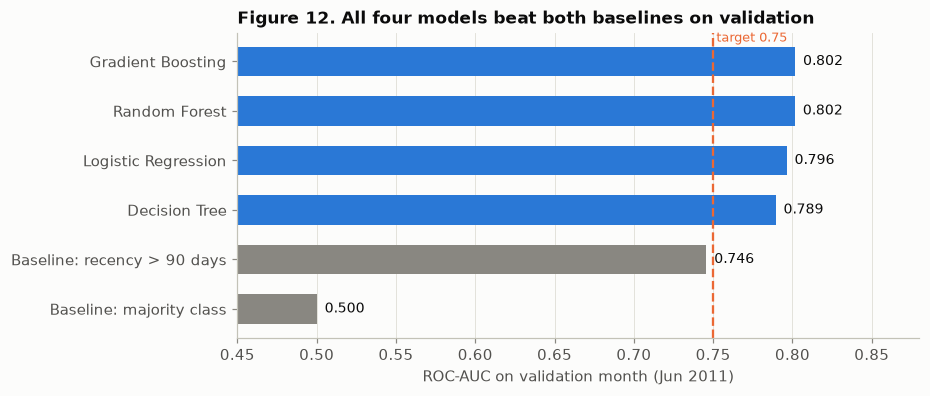

In [8]:
order = val_table.index[::-1]
fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [viz.MUTED if n.startswith("Baseline") else viz.BLUE for n in order]
ax.barh(order, val_table.loc[order, "roc_auc"], color=colors, height=0.6)
for y, n in enumerate(order):
    ax.text(val_table.loc[n, "roc_auc"], y, f"  {val_table.loc[n, 'roc_auc']:.3f}", va="center", fontsize=9)
ax.axvline(0.75, color=viz.ORANGE, lw=1.5, ls="--"); ax.text(0.752, len(order) - 0.6, "target 0.75", color=viz.ORANGE, fontsize=8.5)
ax.set_xlim(0.45, 0.88); ax.set_xlabel("ROC-AUC on validation month (Jun 2011)"); ax.grid(axis="y", visible=False)
ax.set_title("Figure 12. All four models beat both baselines on validation")
viz.save(fig, "fig12_validation_comparison"); plt.show()

In [9]:
model_names = list(specs)
best_name = max(model_names, key=lambda n: (round(val_rows[n]["roc_auc"], 3), val_rows[n]["pr_auc"]))
threshold = val_rows[best_name]["threshold"]
print(f"Selected model: {best_name}  (validation ROC-AUC {val_rows[best_name]['roc_auc']:.4f}, "
      f"PR-AUC {val_rows[best_name]['pr_auc']:.4f}); decision threshold = {threshold}")

Selected model: Gradient Boosting  (validation ROC-AUC 0.8016, PR-AUC 0.8540); decision threshold = 0.5


**Interpretation (selection).** Both baselines were beaten clearly. The majority-class model has AUC 0.50 and macro-F1 0.39. The recency rule (*no order for 90 days ⇒ churn*) reaches AUC 0.746, and every ML model improves on it by about 0.04–0.06 AUC, showing that combining several behaviours adds value beyond recency alone.

**Final model: Gradient Boosting.** It has the highest validation ROC-AUC (0.8016) and PR-AUC (0.854). The difference from Random Forest (0.8015) is far smaller than the bootstrap 95% CI (±0.014), so the two are statistically tied. The tie was broken by PR-AUC, and Gradient Boosting also has practical advantages: the saved model is small (about 0.2 MB, far smaller than a 400-tree forest), it predicts fast, and it handles missing values natively. Logistic Regression is a close third (0.796) and is kept as the interpretable reference model. The macro-F1-optimal threshold on validation is **0.50**.

## 5. Final evaluation on the untouched test month (Sep 2011)
Each model is re-fitted with its tuned settings on all cutoffs Dec 2010 – Jun 2011 and scored **once** on the test month, using the threshold chosen on validation. All models are reported for transparency, but the selection above was made **before** looking at these numbers.

In [10]:
Xrf, yrf = S["refit"][M.FEATURES], S["refit"][TARGET]
Xte, yte = S["test"][M.FEATURES], S["test"][TARGET]
final, test_proba, test_rows = {}, {}, {}
for name, spec in specs.items():
    final[name] = M.make_pipeline(spec).set_params(**tuned[name]).fit(Xrf, yrf)
    test_proba[name] = final[name].predict_proba(Xte)[:, 1]
    test_rows[name] = M.evaluate(yte, test_proba[name], val_rows[name]["threshold"])
d = M.make_dummy().fit(Xrf, yrf)
test_proba["Baseline: majority class"] = d.predict_proba(Xte)[:, 1]
test_rows["Baseline: majority class"] = M.evaluate(yte, test_proba["Baseline: majority class"], 0.5)
test_proba["Baseline: recency > 90 days"] = M.RecencyRule().predict_proba(Xte)[:, 1]
test_rows["Baseline: recency > 90 days"] = M.evaluate(yte, test_proba["Baseline: recency > 90 days"], M.RECENCY_RULE_THRESHOLD)

test_table = pd.DataFrame(test_rows).T[cols + ["accuracy", "brier"]].sort_values("roc_auc", ascending=False)
test_table["AUC 95% CI"] = [("[{:.3f}, {:.3f}]".format(*boot_auc(yte, test_proba[n])) if n in specs else "")
                            for n in test_table.index]
print(f"Test month: {len(yte):,} customers, churn rate {yte.mean():.1%}")
test_table

Test month: 4,323 customers, churn rate 50.5%


,roc_auc,pr_auc,macro_f1,f1_churn,precision_churn,recall_churn,balanced_accuracy,threshold,accuracy,brier,AUC 95% CI
Random Forest,0.7741,0.7445,0.6915,0.7460,0.6532,0.8694,0.6995,0.4700,0.7011,0.1932,"[0.760, 0.787]"
Gradient Boosting,0.7736,0.7458,0.6933,0.7352,0.6613,0.8277,0.6978,0.5000,0.6991,0.1930,"[0.759, 0.786]"
Logistic Regression,0.7705,0.7359,0.7024,0.7307,0.6776,0.7929,0.7042,0.5500,0.7051,0.1957,"[0.756, 0.784]"
Decision Tree,0.7639,0.7125,0.6728,0.7353,0.6380,0.8676,0.6830,0.4800,0.6847,0.1966,"[0.749, 0.778]"
Baseline: recency > 90 days,0.7078,0.6801,0.6631,0.6837,0.6520,0.7186,0.6638,0.2466,0.6644,0.2514,
Baseline: majority class,0.5000,0.5047,0.3354,0.6709,0.5047,1.0000,0.5000,0.5000,0.5047,0.4953,


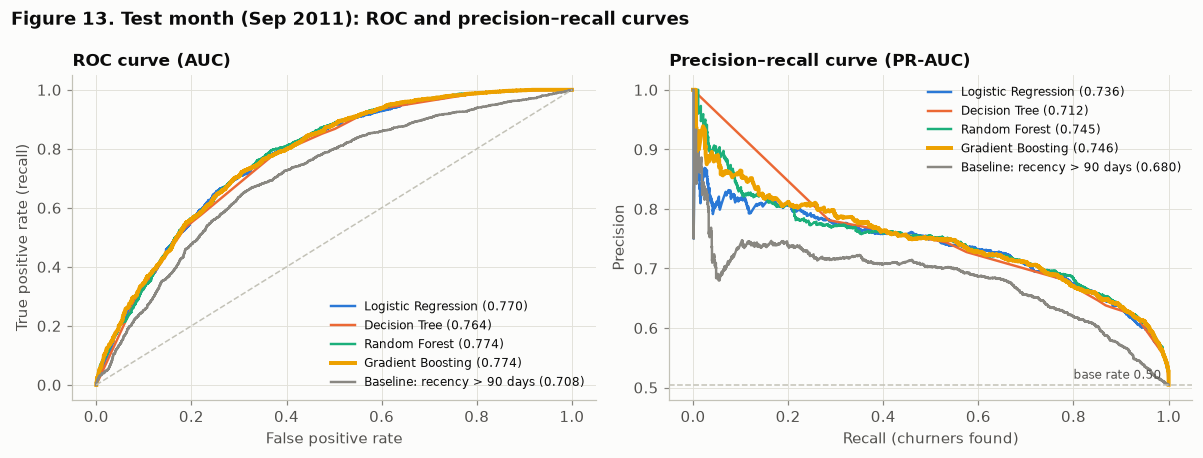

In [11]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
plot_names = model_names + ["Baseline: recency > 90 days"]
for i, n in enumerate(plot_names):
    color = viz.MUTED if n.startswith("Baseline") else viz.SERIES[i]
    lw = 2.6 if n == best_name else 1.6
    fpr, tpr, _ = roc_curve(yte, test_proba[n])
    a1.plot(fpr, tpr, color=color, lw=lw, label=f"{n} ({test_rows[n]['roc_auc']:.3f})")
    pr, rc, _ = precision_recall_curve(yte, test_proba[n])
    a2.plot(rc, pr, color=color, lw=lw, label=f"{n} ({test_rows[n]['pr_auc']:.3f})")
a1.plot([0, 1], [0, 1], color=viz.AXIS, ls="--", lw=1)
a1.set_xlabel("False positive rate"); a1.set_ylabel("True positive rate (recall)"); a1.set_title("ROC curve (AUC)")
a2.axhline(yte.mean(), color=viz.AXIS, ls="--", lw=1); a2.text(0.80, yte.mean() + 0.01, f"base rate {yte.mean():.2f}", fontsize=8, color=viz.INK_2)
a2.set_xlabel("Recall (churners found)"); a2.set_ylabel("Precision"); a2.set_title("Precision–recall curve (PR-AUC)")
for a in (a1, a2): a.legend(fontsize=7.8, loc="lower right" if a is a1 else "upper right")
fig.suptitle("Figure 13. Test month (Sep 2011): ROC and precision–recall curves", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); viz.save(fig, "fig13_test_roc_pr"); plt.show()

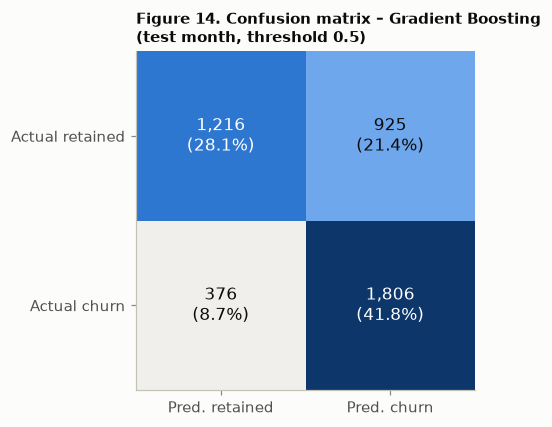

threshold           0.5000
accuracy            0.6991
balanced_accuracy   0.6978
precision_churn     0.6613
recall_churn        0.8277
f1_churn            0.7352
macro_f1            0.6933
roc_auc             0.7736
pr_auc              0.7458
brier               0.1930


In [12]:
r = test_rows[best_name]
cm = np.array([[r["tn"], r["fp"]], [r["fn"], r["tp"]]])
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cm, cmap=viz.SEQ_BLUE); ax.grid(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n({cm[i, j] / cm.sum():.1%})", ha="center", va="center", fontsize=11,
                color="#ffffff" if cm[i, j] > cm.max() * 0.6 else viz.INK)
ax.set_xticks([0, 1], ["Pred. retained", "Pred. churn"]); ax.set_yticks([0, 1], ["Actual retained", "Actual churn"])
ax.set_title(f"Figure 14. Confusion matrix – {best_name}\n(test month, threshold {threshold})", fontsize=10)
viz.save(fig, "fig14_confusion_matrix"); plt.show()
print(pd.Series(r).drop(["tn", "fp", "fn", "tp"]).round(4).to_string())

In [13]:
# Same model, but with the threshold re-chosen for the new base rate (diagnostic only: uses test labels)
oracle_th = M.best_threshold(yte, test_proba[best_name])
print(f"Validation-chosen threshold {threshold}: macro-F1 {r['macro_f1']:.4f}")
print(f"Best possible threshold on test {oracle_th}: macro-F1 {M.evaluate(yte, test_proba[best_name], oracle_th)['macro_f1']:.4f}  (not used for reporting)")
print(f"Mean predicted churn probability on test: {test_proba[best_name].mean():.3f} vs actual churn rate {yte.mean():.3f}")

Validation-chosen threshold 0.5: macro-F1 0.6933
Best possible threshold on test 0.59: macro-F1 0.7064  (not used for reporting)
Mean predicted churn probability on test: 0.540 vs actual churn rate 0.505


**Interpretation (test month).** On the untouched September 2011 cohort, the selected Gradient Boosting model achieves **ROC-AUC 0.774 (95% CI 0.759–0.786)**, **PR-AUC 0.746** against a base rate of 0.505, and **macro-F1 0.693** against 0.335 for the majority baseline. **All three pre-registered success criteria are met.** It again beats the recency rule (AUC 0.708) by a clear margin.

Test scores are lower than validation scores (0.774 vs 0.802). This is expected: the test outcome window (Sep–Nov) is the pre-Christmas peak, when many customers who looked inactive come back, and the churn rate falls from about 64% to 50.5% (EDA Figure 10). The model was trained mostly on higher-churn months, so it **over-predicts churn slightly** (mean predicted probability 0.54 vs actual 0.505). At the 0.50 threshold it favours **recall (83% of churners found)** over precision (66%). The confusion matrix shows the cost: 925 retained customers (43% of them) would also be contacted.

A threshold re-tuned for this new base rate (0.59) would raise macro-F1 only slightly (0.693 → 0.706). It is reported as a diagnostic, not used, because it is chosen with test labels. In production, the threshold should be re-checked every season.

## 6. What drives the predictions? (interpretation)

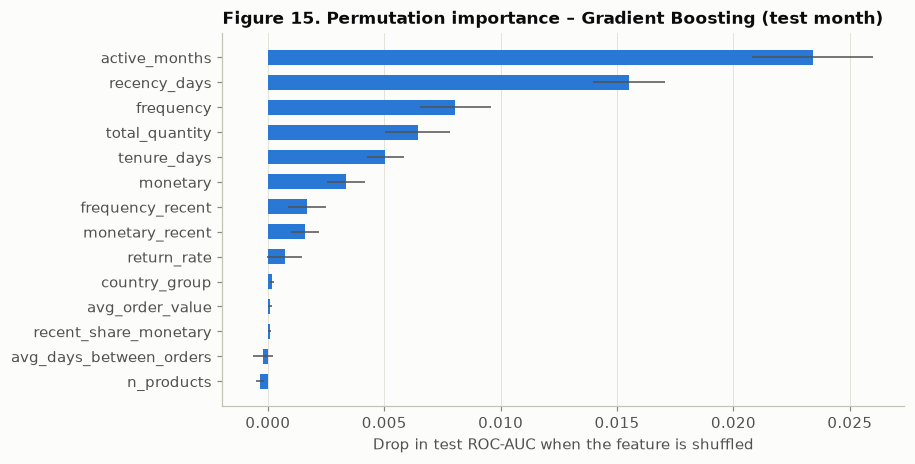

,mean AUC drop,std
active_months,0.0234,0.0026
recency_days,0.0155,0.0016
frequency,0.0080,0.0015
total_quantity,0.0064,0.0014
tenure_days,0.0050,0.0008
monetary,0.0034,0.0008
frequency_recent,0.0017,0.0008
monetary_recent,0.0016,0.0006
return_rate,0.0007,0.0008
country_group,0.0002,0.0001


In [14]:
pi = permutation_importance(final[best_name], Xte, yte, scoring="roc_auc", n_repeats=10,
                            random_state=RANDOM_STATE, n_jobs=-1)
imp = (pd.DataFrame({"mean AUC drop": pi.importances_mean, "std": pi.importances_std}, index=M.FEATURES)
       .sort_values("mean AUC drop", ascending=False))
fig, ax = plt.subplots(figsize=(8, 4.4))
t = imp.iloc[::-1]
ax.barh(t.index, t["mean AUC drop"], xerr=t["std"], color=viz.BLUE, height=0.6, error_kw=dict(ecolor=viz.INK_2, lw=1))
ax.set_xlabel("Drop in test ROC-AUC when the feature is shuffled"); ax.grid(axis="y", visible=False)
ax.set_title(f"Figure 15. Permutation importance – {best_name} (test month)")
viz.save(fig, "fig15_permutation_importance"); plt.show()
imp

In [15]:
lr = final["Logistic Regression"]
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=lr.named_steps["prep"].get_feature_names_out())
coef_table = coef.to_frame("coefficient (log1p-standardised)").assign(odds_ratio=np.exp(coef)).sort_values("coefficient (log1p-standardised)")
coef_table

,coefficient (log1p-standardised),odds_ratio
active_months,-0.5900,0.5543
frequency_recent,-0.3844,0.6808
frequency,-0.2673,0.7654
country_group_France,-0.2499,0.7789
country_group_Germany,-0.2039,0.8155
monetary,-0.1520,0.8590
total_quantity,-0.1234,0.8839
missingindicator_avg_days_between_orders,-0.0821,0.9212
recent_share_monetary,-0.0624,0.9396
avg_order_value,-0.0485,0.9527


In [16]:
tree = final["Decision Tree"]
print(export_text(tree.named_steps["clf"], feature_names=list(tree.named_steps["prep"].get_feature_names_out()),
                  max_depth=3, decimals=1, show_weights=False))

|--- frequency <= 3.5
|   |--- active_months <= 1.5
|   |   |--- tenure_days <= 50.6
|   |   |   |--- total_quantity <= 163.0
|   |   |   |   |--- class: 1
|   |   |   |--- total_quantity >  163.0
|   |   |   |   |--- class: 1
|   |   |--- tenure_days >  50.6
|   |   |   |--- monetary <= 278.0
|   |   |   |   |--- class: 1
|   |   |   |--- monetary >  278.0
|   |   |   |   |--- class: 1
|   |--- active_months >  1.5
|   |   |--- monetary_recent <= 505.8
|   |   |   |--- active_months <= 2.5
|   |   |   |   |--- class: 1
|   |   |   |--- active_months >  2.5
|   |   |   |   |--- class: 1
|   |   |--- monetary_recent >  505.8
|   |   |   |--- avg_days_between_orders <= 96.7
|   |   |   |   |--- class: 0
|   |   |   |--- avg_days_between_orders >  96.7
|   |   |   |   |--- class: 0
|--- frequency >  3.5
|   |--- active_months <= 5.5
|   |   |--- recency_days <= 141.4
|   |   |   |--- total_quantity <= 585.5
|   |   |   |   |--- class: 0
|   |   |   |--- total_quantity >  585.5
|   |   |  

**Interpretation (feature importance).**
* **Permutation importance** (how much test AUC drops when one feature is shuffled) puts **active_months** (number of distinct months with a purchase) first, followed by **recency_days**, **frequency**, **total_quantity** and **tenure_days**. Regular, long-standing buyers who ordered recently are retained. Country, average order value and return rate add almost nothing, which agrees with the χ² test in notebook 02. Some importances are about 0 (n_products, avg_days_between_orders) because their information is **shared with correlated features**: shuffling one leaves its twins intact.
* **Logistic Regression coefficients** tell the same story. More active months (odds ratio 0.55 per standard deviation), more recent orders and higher frequency lower the churn odds, while higher recency raises them. A few signs look counter-intuitive (for example `monetary_recent` is positive). This is the **multicollinearity effect** seen in Figure 8: once `frequency_recent` is in the model, the extra spend variable only adjusts for it. That is why individual coefficients are not interpreted on their own.
* **The Decision Tree's first rules are easy to explain.** Customers with **≤ 3 orders in the year and only 1 active month** are mostly churners. Customers with **> 3 orders who bought within the last ~140 days** are mostly retained.

## 7. Business view — who to contact and how much revenue is at risk

In [17]:
lift = M.lift_table(yte, test_proba[best_name], S["test"]["monetary"])
lift

,customers,churners,churn_rate,mean_risk,past_365d_spend,lift,cum_share_of_churners
decile,,,,,,,
1,433,355,0.8199,0.8150,"74,156.0200",1.6243,0.1627
2,432,326,0.7546,0.7757,"139,286.3200",1.4951,0.3121
3,432,298,0.6898,0.7439,"174,128.4700",1.3667,0.4487
4,432,285,0.6597,0.6971,"236,142.2300",1.3070,0.5793
5,433,271,0.6259,0.6349,"330,766.3900",1.2400,0.7035
6,432,205,0.4745,0.5706,"393,653.3400",0.9402,0.7974
7,432,202,0.4676,0.4802,"509,018.2100",0.9264,0.8900
8,432,146,0.3380,0.3606,"685,412.5000",0.6696,0.9569
9,432,71,0.1644,0.2356,"1,159,463.7500",0.3256,0.9895


Customers flagged as likely churners: 2,731 of 4,323 (63.2%)
Their spend in the previous 365 days: £1,508,851 of £8,005,952 (18.8%)
Expected revenue at risk = sum(p_churn x past-year spend): £1,895,787
Top 20% riskiest customers: churn rate 78.7% vs 50.5% overall; they contain 31.2% of all churners


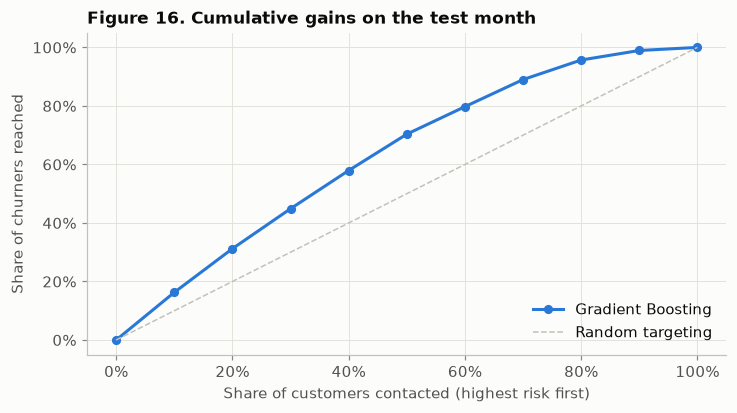

In [18]:
p = test_proba[best_name]; spend = S["test"]["monetary"].to_numpy()
flagged = p >= threshold
print(f"Customers flagged as likely churners: {flagged.sum():,} of {len(p):,} ({flagged.mean():.1%})")
print(f"Their spend in the previous 365 days: £{spend[flagged].sum():,.0f} of £{spend.sum():,.0f} ({spend[flagged].sum() / spend.sum():.1%})")
print(f"Expected revenue at risk = sum(p_churn x past-year spend): £{(p * spend).sum():,.0f}")
top = lift.iloc[:2]
print(f"Top 20% riskiest customers: churn rate {top['churners'].sum() / top['customers'].sum():.1%} "
      f"vs {yte.mean():.1%} overall; they contain {lift['cum_share_of_churners'].iloc[1]:.1%} of all churners")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
x = np.r_[0, np.arange(1, 11) / 10]
ax.plot(x, np.r_[0, lift["cum_share_of_churners"]], color=viz.BLUE, marker="o", ms=5, label=best_name)
ax.plot([0, 1], [0, 1], color=viz.AXIS, ls="--", lw=1, label="Random targeting")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Share of customers contacted (highest risk first)"); ax.set_ylabel("Share of churners reached")
ax.legend(loc="lower right"); ax.set_title("Figure 16. Cumulative gains on the test month")
viz.save(fig, "fig16_cumulative_gains"); plt.show()

**Interpretation (business value).** Ranking customers by predicted risk is useful for targeting. The **top 10% riskiest customers churn at 82%** (lift 1.62×) and the top 20% churn at 79% versus 50.5% overall. Contacting the riskiest half of customers reaches 70% of all churners.

High-risk customers are mostly **small, occasional buyers**. The 63% of customers flagged at the 0.50 threshold account for only 19% of last year's spend, while the lowest-risk decile alone holds £4.3M of the £8.0M. The probability-weighted **revenue at risk** (Σ p(churn) × past-year spend) is about **£1.9M**. This is a rough planning figure, not a forecast of lost sales, because a churned customer may come back later and past spend does not equal future spend. In practice the retention team should sort by **risk × value**, not by risk alone.

## 8. Save the final pipeline and results

In [19]:
MODELS.mkdir(exist_ok=True)
bundle = {"pipeline": final[best_name], "model_name": best_name, "threshold": threshold,
          "features": M.FEATURES, "trained_on_cutoffs": [str(c.date()) for c in M.REFIT_CUTOFFS],
          "sklearn_version": sklearn.__version__}
joblib.dump(bundle, MODELS / "churn_model.joblib")

def clean(d): return {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in d.items()}
results = {
    "split": {k: {"rows": int(len(v)), "churn_rate": round(float(v[TARGET].mean()), 4)} for k, v in S.items()},
    "train_cutoffs": [str(c.date()) for c in M.TRAIN_CUTOFFS], "validation_cutoff": str(M.VAL_CUTOFF.date()),
    "test_cutoff": str(M.TEST_CUTOFF.date()), "refit_cutoffs": [str(c.date()) for c in M.REFIT_CUTOFFS],
    "selected_model": best_name, "threshold": threshold,
    "tuned_params": {n: {k: (float(v) if isinstance(v, (float, np.floating)) else v) for k, v in p.items()} for n, p in tuned.items()},
    "train_group_cv_auc": {n: [round(float(s.mean()), 4), round(float(s.std()), 4)] for n, s in cv_auc.items()},
    "validation": {n: clean(v) for n, v in val_rows.items()},
    "test": {n: clean(v) for n, v in test_rows.items()},
    "permutation_importance": imp["mean AUC drop"].round(4).to_dict(),
}
(REPORTS / "model_results.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
print("Saved models/churn_model.joblib and reports/model_results.json")

Saved models/churn_model.joblib and reports/model_results.json


## 9. Conclusions and limitations

### Conclusions
1. A leakage-safe, time-based pipeline turns 1M raw transaction lines into 42,832 labelled customer snapshots across 10 monthly cutoffs.
2. Four tuned models all beat the majority-class and recency-rule baselines. **Gradient Boosting** was selected on validation (AUC 0.802) and generalises to a later, seasonally different month with **test ROC-AUC 0.774, PR-AUC 0.746 and macro-F1 0.693**, meeting every success criterion set in the problem statement.
3. Churn is driven by **engagement regularity (active months), recency and frequency**. Order size and country matter little.
4. Risk scores give a 1.6× lift in the top decile and support a ranked retention list. Combined with past spend, they give a planning estimate of revenue at risk.

### Limitations
* **Seasonal shift.** Test churn (50.5%) differs from training (≈ 64–66%). Scores and the threshold drift with the season, so monitoring and periodic re-training would be needed.
* **Short history.** Only about 2 years of data, so features use a 365-day window and tenure is right-censored at Dec 2009. Same-season training data from previous years is not available.
* **Behavioural proxy label.** "No purchase in 90 days" is not a cancelled contract. Some "churners" are simply infrequent buyers, which limits achievable accuracy.
* **Limited features.** There is no demographic, marketing, web-browsing or customer-service data, and 22% of transactions have no customer ID and cannot be used.
* **One retailer, 2009–2011.** The results show the method works, not that it predicts today's retail churn without re-validation.
* **Model choice is a near-tie.** RF, GB and LR are within each other's confidence intervals. The choice rests on practicality, not on a significant accuracy gain.

### Possible improvements
Add product-category and seasonality features (e.g. last year's activity in the same month), calibrate probabilities (Platt/isotonic) on recent data, rank by expected value (risk × spend), try survival analysis (time-to-next-purchase), and evaluate on several rolling test months.